---
# Curso: Data Mining
**Docente:** Soledad Espezúa Llerena
---

# <font color=green>Laboratorio: Reducción dimensional con PCA y NMF</font>
## <font color=blue>Caso: los gorriones de Bumpus</font>

En 1898, después de una fuerte tormenta en Providence (Estados Unidos), varios gorriones fueron recogidos y llevados a la Universidad de Brown. Algunos sobrevivieron y otros murieron.

Hermon C. Bumpus registró medidas corporales de las aves para estudiar si ciertas características físicas estaban relacionadas con la supervivencia.

En este laboratorio utilizaremos este caso para comparar dos maneras de reducir dimensionalidad:

- **PCA:** busca direcciones que maximizan sucesivamente la varianza.
- **NMF:** busca reconstruir los datos mediante componentes **aditivas y no negativas**.

<font color=red>**Importante:** ambos métodos son no supervisados. Las variables `Sex` y `Survival` no se utilizarán para construir las componentes. Solo las emplearemos posteriormente para interpretar las representaciones obtenidas.</font>


**Fuente de los datos**:

Bumpus, H. C. (1899). The elimination of the unfit as illustrated by the introduced sparrow, Passer domesticus. Biological Lectures, Marine Biological Laboratory, Woods Hole, 209–226.

Subconjunto de 49 hembras basado en Manly, Navarro Alberto y Gerow (2024), Multivariate Statistical Methods: A Primer (5th ed.).

## <font color=green>Objetivos</font>

1. aplicar PCA sobre variables previamente estandarizadas;
2. interpretar la varianza explicada y las direcciones de proyección de PCA;
3. aplicar NMF sobre datos no negativos;
4. interpretar las matrices \(W\) y \(H\);
5. reconstruir aproximadamente \(X\) mediante \(WH\);
6. comparar PCA y NMF y reconocer por qué requieren distinto preprocesamiento.


# <font color=green>1. Cargamos librerías y datos</font>

Usaremos:

- `pandas` para manipular tablas;
- `seaborn` para las visualizaciones;
- `StandardScaler` para PCA;
- `MinMaxScaler` para NMF;
- `PCA` y `NMF` de `sklearn.decomposition`.


In [1]:
import pandas as pd
import numpy as np
import seaborn as sns

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA, NMF

pd.set_option("display.precision", 3)
sns.set_theme(style="ticks")

# El archivo debe estar en la misma carpeta que el notebook.
df = pd.read_csv("bumpus_136_aves.csv")

print("Dimensiones del dataset:", df.shape)
display(df.head())


Dimensiones del dataset: (136, 13)


,Line,Sex,Age,Survival,Total_length_mm,Alar_extent_mm,Weight_g,Beak_head_mm,Humerus_mm,Femur_mm,Tibiotarsus_mm,Skull_width_mm,Keel_sternum_mm
0,1,Male,Adult,Survived,154.0,241.0,24.5,31.2,17.450,16.967,25.959,14.910,21.082
1,1,Male,Adult,Perished,165.0,240.0,26.5,31.0,18.745,17.882,27.813,15.392,21.514
2,2,Male,Adult,Perished,160.0,245.0,26.1,32.0,18.694,18.009,28.169,15.519,21.387
3,2,Male,Adult,Survived,160.0,252.0,26.9,30.8,18.694,18.009,29.972,15.291,21.361
4,3,Male,Adult,Survived,155.0,243.0,26.9,30.6,18.618,17.882,29.235,15.291,21.488


## <font color=green>2. Entendemos la matriz</font>

Nuestra **unidad de análisis** es:

> **una fila = un ave**

Trabajaremos con nueve medidas morfológicas:

- longitud total;
- extensión de las alas;
- peso;
- longitud asociada a pico y cabeza;
- húmero;
- fémur;
- tibiotarso;
- ancho del cráneo;
- quilla del esternón.

Las variables `Sex` y `Survival` se reservarán para interpretación posterior.


In [2]:
variables = [
    "Total_length_mm",     # Longitud total del cuerpo (mm)
    "Alar_extent_mm",      # Extensión de las alas (mm)
    "Weight_g",            # Peso del ave (g)
    "Beak_head_mm",        # Longitud del pico y cabeza (mm)
    "Humerus_mm",          # Longitud del húmero (mm)
    "Femur_mm",            # Longitud del fémur (mm)
    "Tibiotarsus_mm",      # Longitud del tibiotarso (mm)
    "Skull_width_mm",      # Ancho del cráneo (mm)
    "Keel_sternum_mm"      # Longitud de la quilla del esternón (mm)
]

print("Distribución por sexo:")
display(df["Sex"].value_counts())

print("Distribución por supervivencia:")
display(df["Survival"].value_counts())

print("Resumen de las variables morfológicas:")
display(df[variables].describe().T.round(2))


Distribución por sexo:


Sex
Male      87
Female    49
Name: count, dtype: int64

Distribución por supervivencia:


Survival
Survived    72
Perished    64
Name: count, dtype: int64

Resumen de las variables morfológicas:


,count,mean,std,min,25%,50%,75%,max
Total_length_mm,136.0,159.54,3.56,152.00,157.00,160.00,162.00,167.00
Alar_extent_mm,136.0,245.19,5.52,230.00,242.00,246.00,249.00,256.00
Weight_g,136.0,25.52,1.48,22.60,24.58,25.55,26.50,31.00
Beak_head_mm,136.0,31.57,0.70,29.80,31.10,31.60,32.02,33.40
Humerus_mm,136.0,18.59,0.59,16.74,18.23,18.62,19.01,19.81
Femur_mm,136.0,18.11,0.61,16.59,17.82,18.11,18.57,19.48
Tibiotarsus_mm,136.0,28.79,1.03,25.68,28.24,28.78,29.52,31.24
Skull_width_mm,136.0,15.30,0.38,14.00,15.04,15.29,15.52,16.26
Keel_sternum_mm,136.0,21.33,1.01,18.64,20.55,21.36,21.98,23.55


# <font color=green>3. ¿Por qué comenzar con las 49 hembras?</font>

Machos y hembras presentan diferencias morfológicas. Si comenzamos directamente con las 136 aves, esas diferencias podrían dominar las primeras componentes.

Por ello:

1. primero analizaremos solamente las **49 hembras**;
2. luego volveremos al conjunto completo para observar qué cambia.

Esta estrategia permite estudiar primero un grupo más homogéneo.


In [3]:
# Filtramos las hembras.
hembras = df[df["Sex"] == "Female"].copy()

print("Número de hembras:", hembras.shape[0])

# Supervivencia se muestra solo como información del caso.
display(hembras["Survival"].value_counts())


Número de hembras: 49


Survival
Perished    28
Survived    21
Name: count, dtype: int64

# <font color=green>PARTE I. Repaso de PCA</font>

El foco de esta sesión será NMF, por lo que PCA se revisará de manera breve.

Usaremos la notación:

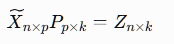

donde:

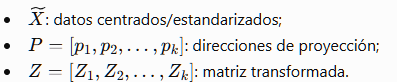


## <font color=green>4. Antes de PCA: StandardScaler</font>

PCA trabaja con **varianza**. Si las variables tienen escalas o dispersiones diferentes, algunas pueden dominar la solución.

Por ello, una buena práctica habitual es **estandarizar** antes de aplicar PCA:

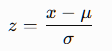

Después de estandarizar, cada atributo tiene aproximadamente:

- media \(0\);
- desviación estándar \(1\).


In [4]:
# X contiene únicamente las variables morfológicas.
X = hembras[variables].copy()

# Creamos el estandarizador.
scaler_std = StandardScaler()

# fit_transform:
# 1. calcula media y desviación de cada atributo;
# 2. transforma los datos usando esos valores.
X_std = scaler_std.fit_transform(X)

print("Media aproximada de cada variable:")
print(np.round(X_std.mean(axis=0), 2))

print("\nDesviación estándar aproximada:")
print(np.round(X_std.std(axis=0), 2))

Media aproximada de cada variable:
[-0. -0.  0.  0. -0. -0. -0. -0.  0.]

Desviación estándar aproximada:
[1. 1. 1. 1. 1. 1. 1. 1. 1.]


## <font color=green>5. Aplicamos PCA</font>

Calcularemos todas las componentes para observar cuánta varianza explica cada una.


In [5]:
# Creamos PCA sin limitar todavía el número de componentes.
pca = PCA()

# Z contiene los datos proyectados.
# Su dimensión será n x p porque aquí conservamos todas las componentes.
Z = pca.fit_transform(X_std)

# En sklearn, components_ tiene forma k x p.
# Transponemos para obtener P con forma p x k:
# cada columna de P es una dirección de proyección.
P = pca.components_.T

print("Dimensión de X_std:", X_std.shape)
print("Dimensión de P:", P.shape)
print("Dimensión de Z:", Z.shape)

Dimensión de X_std: (49, 9)
Dimensión de P: (9, 9)
Dimensión de Z: (49, 9)


### <font color=blue>Varianza explicada</font>

Cada componente \(Z_j\) tiene asociada una varianza explicada.

La primera componente explica la mayor varianza; la segunda, la siguiente mayor, y así sucesivamente.


In [6]:
nombres_z = [f"Z{i+1}" for i in range(len(variables))]
tabla_varianza = pd.DataFrame({
    "Componente": nombres_z,
    "Proporcion": pca.explained_variance_ratio_
})

tabla_varianza["Porcentaje"] = 100 * tabla_varianza["Proporcion"]
tabla_varianza["Acumulada"] = 100 * tabla_varianza["Proporcion"].cumsum()

display(tabla_varianza.round(2))


,Componente,Proporcion,Porcentaje,Acumulada
0,Z1,0.67,66.50,66.50
1,Z2,0.09,9.49,75.99
2,Z3,0.07,6.87,82.87
3,Z4,0.05,5.20,88.07
4,Z5,0.04,4.14,92.20
5,Z6,0.03,2.95,95.16
6,Z7,0.02,1.97,97.12
7,Z8,0.02,1.62,98.74
8,Z9,0.01,1.26,100.00


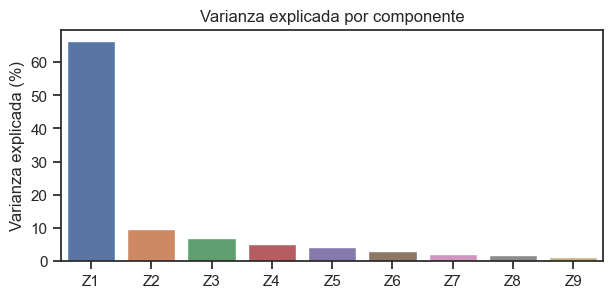

In [7]:
# Gráfico de varianza explicada por componente.
ax = sns.barplot(
    data=tabla_varianza,
    x="Componente",
    y="Porcentaje",
    hue="Componente",
    legend=False
)

ax.set(
    title="Varianza explicada por componente",
    xlabel="",
    ylabel="Varianza explicada (%)"
)

ax.figure.set_size_inches(7, 3)

Despues de calculada la varianza explicada, podemos decidir cuántas conservar.

### <font color=red> Para visualizar utilizaremos solo las dos primeras componentes (Z1 y Z2), que en conjunto explican aproximadamente el 80 % de la varianza total.</font>
Elegiremos el menor número de componentes que permita conservar al menos el 80 % de la varianza acumulada.

### <font color=blue>Direcciones de proyección \(P\)</font>

Los elementos de \(P\) indican cómo participa cada atributo original en cada dirección de proyección.

Nos concentraremos en las dos primeras.


In [ ]:
P_df = pd.DataFrame(P,index=variables,columns=nombres_z) # Direcciones P

display(P_df[["Z1", "Z2"]].round(2))

ax = sns.heatmap(
    P_df[["Z1", "Z2"]],
    annot=True,
    fmt=".2f",
    cmap="vlag",
    center=0
)

ax.set(
    title="Direcciones de proyección de PCA",
    xlabel="",
    ylabel=""
)

ax.figure.set_size_inches(6, 5)

### <font color=blue>¿Cómo interpretar las direcciones?</font>
Cada valor de la tabla es el peso (loading) de un atributo original en la dirección de proyección.
Cuanto mayor sea su valor absoluto, mayor es su contribución a esa componente.

En Z1 todos los pesos son positivos y bastante parecidos:

```
Z1 = [0.32Total + 0.34Alar + 0.31Peso + 0.36PicoCabeza + 0.37Húmero + 0.34Fémur+ 0.34Tibiotarso + 0.32Cráneo + 0.29Quilla]
```
Entonces Z1 representa principalmente el tamaño corporal general del ave.


En cambio en Z2 aparecen pesos positivos y negativos:

```
Z2 = [-0.42Total - 0.10Alar - 0.37Peso + 0.09PicoCabeza + 0.17Húmero + 0.48Fémur+ 0.46Tibiotarso - 0.03Cráneo - 0.43Quilla]
```
Positivos fuertes
- Fémur: 0.48
- Tibiotarso: 0.46

Negativos fuertes
- Longitud total: −0.42
- Quilla del esternón: −0.43
- Peso: −0.37

Por tanto Z2 no representa “tamaño”. Representa representa un contraste de aves con extremidades inferiores relativamente más desarrolladas frente a aves con mayor longitud/peso corporal y mayor quilla esternal.


Observe qué atributos presentan valores de mayor magnitud en cada dirección.
- Valores de mayor magnitud indican mayor contribución del atributo.
- Cuando los pesos tienen signos opuestos, la componente representa un contraste entre grupos de variables.
<font color=red>La interpretación no surge del nombre `Z1` o `Z2`; surge de los pesos de las variables originales.</font>

## <font color=green>6. Visualizamos Z1 y Z2</font>

La variable `supervivencia` **no fue utilizada por PCA**. La agregamos después únicamente para colorear los puntos.

Para explorar visualmente la estructura de los datos, representaremos las primeras dos componentes.


In [ ]:
Z_df = pd.DataFrame(Z[:, :2],columns=["Z1", "Z2"], index=hembras.index)

Z_df["Survival"] = hembras["Survival"]

ax = sns.scatterplot(
    data=Z_df,
    x="Z1",
    y="Z2",
    hue="Survival", # supervivencia
    s=80
)

ax.set_title("PCA de las 49 hembras")
ax.figure.set_size_inches(7, 5)

### <font color=blue>Interpretación</font>

El estudio original de Bumpus sugirió que determinadas características morfológicas estaban asociadas con la supervivencia. Sin embargo, PCA no utiliza `Survival`; busca únicamente las direcciones que explican mayor variabilidad en las medidas corporales.

En la proyección de las dos primeras componentes Z1 y Z2 se observa superposición entre sobrevivientes y no sobrevivientes. Por ello, las dos primeras componentes no permiten separar claramente ambos grupos.


# <font color=green>PARTE II. NMF </font>

NMF busca aproximar la matriz de datos mediante:

image.png


con la restricción:

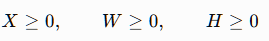


Si X tiene dimensión n x p:
- W tiene dimensión n x k;
- H tiene dimensión k x p.

Interpretación:

- **W:** nueva representación de las observaciones usando \(k\) factores;
- **H:** indica cómo se forma cada factor a partir de los atributos originales.


## <font color=green>7. ¿Por qué no usamos StandardScaler en NMF?</font>

`StandardScaler` puede generar valores negativos.

NMF exige datos no negativos.

Por ello, en este caso usaremos `MinMaxScaler`, que lleva cada variable al intervalo \([0,1]\).


In [ ]:
# Ahora aplicamos Min-Max.
scaler_mm = MinMaxScaler()

X_pos = scaler_mm.fit_transform(X)

print("Mínimo de X_mm:", X_pos.min())
print("Máximo de X_mm:", X_pos.max())


## <font color=green>8. Aplicamos NMF con dos factores</font>

Usaremos \(k=2\) para poder visualizar fácilmente la nueva representación.


In [ ]:
nmf = NMF(
    n_components=2,   # número de factores que queremos obtener
    init="random",      # Inicializa W y H con valores aleatorios
    random_state=1,   # reproducibilidad
    max_iter=2000     # máximo de iteraciones
)

# fit_transform aprende W y H.
# El resultado devuelto por fit_transform es W.
W = nmf.fit_transform(X_pos)

# components_ contiene H.
H = nmf.components_

print("Dimensión de X_pos:", X_pos.shape)
print("Dimensión de W:", W.shape)
print("Dimensión de H:", H.shape)


## <font color=green>9. ¿Qué significa \(H\)?</font>

Cada fila de \(H\) representa un factor (componente).

Cada columna corresponde a un atributo original.

Un valor alto indica que ese atributo tiene una participación importante en el factor.


In [ ]:
H_df = pd.DataFrame(H,index=["NMF1", "NMF2"],columns=variables)

display(H_df.round(2))

ax = sns.heatmap(
    H_df,
    annot=True,
    fmt=".2f",
    cmap="Blues"
)

ax.set(
    title="Matriz H: composición de los factores NMF",
    xlabel="Atributos originales",
    ylabel="Factor"
)

ax.figure.set_size_inches(9, 3)

<font color=red>Los factores son patrones matemáticos sobre las variables escaladas. La interpretación debe justificarse observando \(H\).</font>


## <font color=green>10. ¿Qué significa \(W\)?</font>

Cada fila de \(W\) corresponde a un ave.

Cada columna indica cuánto participa cada factor NMF en esa observación.

Representaremos las aves usando `NMF1` y `NMF2`.


In [ ]:
# W contiene la nueva representación de cada ave
# usando los dos factores encontrados por NMF.
W_df = pd.DataFrame(W,columns=["NMF1", "NMF2"],index=hembras.index)

# Agregamos Survival SOLO para visualizar e interpretar.
# Esta variable NO fue utilizada para calcular NMF.
W_df["Survival"] = hembras["Survival"]

display(W_df.head())

# Cada punto representa un ave.
# Su posición depende únicamente de NMF1 y NMF2.
# El color indica posteriormente si el ave sobrevivió o murió.
ax = sns.scatterplot(
    data=W_df,
    x="NMF1",
    y="NMF2",
    hue="Survival",
    s=80
)

ax.set_title("Representación NMF de las 49 hembras")
ax.figure.set_size_inches(7, 5)

**Importante**: NMF es no supervisado. `Survival` no se utiliza para construir los factores. Se agrega posteriormente únicamente para interpretar la representación obtenida.

### <font color=blue>Pregunta</font>

¿La estructura observada es igual a la obtenida con PCA?

No tiene por qué serlo.

PCA y NMF optimizan criterios diferentes:

- PCA calcula direcciones de proyección que maximizan sucesivamente la varianza.
- NMF busca una reconstrucción basada en factores no negativos.


## <font color=green>11. Reconstruimos la matriz original</font>

NMF no reproduce necesariamente los datos de forma exacta.

Construye una aproximación:

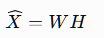

En Python, el operador `@` representa **multiplicación matricial**.


In [ ]:
# Reconstrucción aproximada de la matriz escalada.
X_reconstruida = W @ H

print("Dimensión de X original escalada:", X_pos.shape)
print("Dimensión de X reconstruida:", X_reconstruida.shape)

# sklearn calcula también el error de reconstrucción.
print("Error de reconstrucción NMF:", round(nmf.reconstruction_err_, 3))

### <font color=blue>¿Qué significa el error?</font>

Cuanto menor sea el error, más cercana es la reconstrucción \(WH\) a los datos originales escalados.

Sin embargo, aumentar el número de factores suele reducir el error.

Por ello, **no debemos escoger \(k\) únicamente buscando el error mínimo**. También debemos considerar:

- cuánto queremos reducir la dimensión;
- interpretabilidad;
- complejidad de la representación.


## <font color=green>12. ¿Cómo elegir el número de factores (k)?</font>

Hasta ahora usamos (k=2) porque dos factores permiten **visualizar** fácilmente la representación NMF.

Pero eso no significa que (k=2) sea necesariamente la mejor elección para representar los datos.

Una estrategia práctica es probar varios valores de (k) y observar el **error de reconstrucción**

Si (k) aumenta, NMF dispone de más factores para aproximar (X), por lo que el error normalmente disminuye.


> **¿A partir de qué valor de (k) agregar nuevos factores produce una mejora cada vez menor?**

Ese cambio de pendiente se conoce como **criterio del codo**.


In [ ]:
# Probamos distintos números de factores.
# Como tenemos p=9 atributos y buscamos reducir dimensionalidad,
# probaremos valores de k menores que p.

resultados_k = []

for k in range(1, X.shape[1]):

    modelo_k = NMF(
        n_components=k,
        init="random",      # misma forma de inicialización para todos los k
        random_state=1,     # resultados reproducibles
        max_iter=5000       # aumentamos el límite para permitir la convergencia
    )

    # Ajustamos NMF sobre la MISMA matriz X_pos.
    modelo_k.fit(X_pos)

    resultados_k.append({
        "k": k,
        "Error_reconstruccion": modelo_k.reconstruction_err_
    })

errores_k = pd.DataFrame(resultados_k)

display(errores_k.round(3))


### <font color=blue>Visualizamos el error de reconstrucción</font>


In [ ]:
ax = sns.lineplot(
    data=errores_k,
    x="k",
    y="Error_reconstruccion",
    marker="o"
)

ax.set(
    title="Número de factores vs. error de reconstrucción",
    xlabel="Número de factores (k)",
    ylabel="Error de reconstrucción"
)

ax.figure.set_size_inches(7, 4)


### <font color=blue>Interpretación</font>

- El error de reconstrucción disminuye al aumentar \(k\), porque el modelo dispone de más factores para representar los datos.
- **No conviene elegir automáticamente el mayor \(k\)**: perderíamos gran parte del beneficio de reducir la dimensionalidad.
- El **método del codo** propone elegir un valor a partir del cual agregar nuevos factores produce mejoras relativamente pequeñas.
- Si el gráfico **no muestra un codo claro**, el error por sí solo no permite decidir un único \(k\).

En ese caso debemos considerar también:

1. **Reducción:** \(k\) debe ser suficientemente menor que \(p\).
2. **Reconstrucción:** el error debe ser razonablemente bajo.
3. **Interpretabilidad:** los factores de \(H\) deberían tener una interpretación útil.

> **La elección de \(k\) es un compromiso entre error de reconstrucción, simplicidad e interpretabilidad.**


### <font color=blue>Importante para este laboratorio</font>

En las secciones anteriores mantuvimos:

\[
k=2
\]

porque nuestro objetivo era **visualizar** las aves en un espacio bidimensional y comprender \(W\) y \(H\).

Si el objetivo fuera construir una representación final para una aplicación real, deberíamos utilizar el experimento anterior para proponer un \(k\) y luego revisar si los factores obtenidos son interpretables.


# <font color=green>PARTE III. PCA vs. NMF</font>


| PCA | NMF |
|---|---|
| Usa direcciones ortogonales | Los factores no tienen que ser ortogonales |
| Las contribuciones pueden ser positivas o negativas | Las contribuciones son no negativas |
| Maximiza sucesivamente la varianza | Minimiza el error de reconstrucción |
| Suele combinarse con StandardScaler | Requiere datos no negativos; Min-Max puede ser conveniente |
| Resultado transformado: \(Z\) | Resultado reducido: \(W\) |
| Direcciones de proyección: \(P\) | Componentes/patrones: \(H\) |

### Pregunta central

> ¿Cuál de los dos métodos es “mejor”?

No existe una respuesta universal.

Depende del objetivo del análisis y de la estructura que queremos conservar o interpretar.


# <font color=green>PARTE IV. Experimento final: ahora use las 136 aves</font>

Hasta ahora trabajamos únicamente con hembras.

Ahora repetiremos el análisis con las **136 aves** para observar si aparece una estructura diferente.

Esta vez no le daremos todo el código: adapte lo realizado anteriormente.


## <font color=blue>13. Actividad individual</font>

### A. PCA

1. Use las mismas nueve variables.
2. Estandarice con `StandardScaler`.
3. Aplique PCA.
4. Represente Z1 y Z2.
5. Coloree primero por `Sex`.
6. Sin recalcular PCA, coloree después por `Survival`.

### B. NMF

1. Use las mismas nueve variables.
2. Transforme con `MinMaxScaler`.
3. Aplique NMF con `n_components=2`.
4. Represente `NMF1` y `NMF2`.
5. Coloree por `Sex`.

### C. Responda

En un máximo de 8 líneas:

- ¿qué estructura aparece con mayor claridad al trabajar con las 136 aves?
- ¿esa estructura fue utilizada por PCA/NMF para construir la representación?
- ¿qué diferencias observa entre PCA y NMF?
- ¿qué aprendió sobre la importancia del preprocesamiento?


In [ ]:
# Escriba aquí su solución.


## <font color=blue>14. Desafío grupal: Reducción dimensional en su proyecto</font>


Trabajen con la matriz analítica de su proyecto y desarrollen lo siguiente:
1. Seleccionen los atributos numéricos que utilizarán en el análisis. Excluyan identificadores, códigos y otras columnas no analíticas.
2. Apliquen PCA:
   - Estandaricen los atributos con StandardScaler.
   - Obtengan las componentes principales.
   - Determinen cuántas componentes permiten conservar aproximadamente el 80 % de la varianza acumulada.
   - Interpreten Z1 y Z2 a partir de los atributos con mayor peso en las direcciones de proyección.
3. Apliquen NMF sobre los mismos atributos:
   - Transformen los datos con MinMaxScaler.
   - Utilicen inicialmente n_components=2.
   - Interpreten los factores obtenidos a partir de la matriz H, identificando los atributos con mayor peso en cada factor.
4. Comparen ambas técnicas:
   - ¿PCA y NMF resaltan los mismos atributos?
   - ¿Cuál de las dos representaciones resulta más fácil de interpretar en el contexto de su proyecto?
   - ¿Cuál consideran inicialmente más útil para continuar posteriormente con clustering? Justifiquen.
5. Guarden las representaciones obtenidas:
   - matriz transformada de PCA (Z);
   - matriz reducida de NMF (W).
   
   **Entregable**: incluir en el notebook del proyecto los resultados, al menos un gráfico de la representación PCA, un gráfico de la representación NMF y una conclusión grupal de máximo 8 líneas.

---
## <font color=green>Recordar:</font>

1. **PCA y NMF son métodos no supervisados.**
2. **PCA** calcula direcciones de proyección que maximizan sucesivamente la varianza.
3. **NMF** descompone los datos en factores no negativos cuya combinación permite aproximar la matriz original.
4. PCA y NMF no requieren necesariamente el mismo preprocesamiento.
5. En NMF:
   - \(W\) representa las observaciones en el nuevo espacio;
   - \(H\) describe la composición de los factores.
6. Reducir dimensionalidad implica aceptar cierta pérdida de información a cambio de una representación más compacta e interpretable.


### Fuentes del caso

- Bumpus, H. C. (1899). *The elimination of the unfit as illustrated by the introduced sparrow, Passer domesticus*.
- Manly, B. F. J., Navarro Alberto, J. A., & Gerow, K. *Multivariate Statistical Methods: A Primer*.
